# Consigna 2 — Clasificación no temporal de diagnósticos

**Práctica de selección de variables con redes neuronales (IA — Semana 6)**
Autor: Barreto

**Objetivo.** Explorar las 30 características del dataset *Breast Cancer Wisconsin (Diagnostic)* (UCI, id 17), identificar variables relevantes y redundantes, y comparar una RNA (`MLPClassifier`) con las 30 variables contra **la misma arquitectura y particiones** con un subconjunto seleccionado.

> Uso exclusivamente educativo: los resultados **no** constituyen una herramienta clínica.

**Reglas del experimento**
- Entre corridas solo cambia el conjunto de variables (arquitectura, particiones, semilla, preprocesamiento y métricas fijos).
- Partición estratificada: 60 % train / 20 % validación / 20 % prueba. Escalado y selección se ajustan **solo con train**.
- La prueba queda reservada hasta congelar variables y configuración; se evalúa **una vez**.
- Clase positiva = **maligno (1)**. El error más costoso es el **falso negativo** (maligno no detectado), así que el *recall* de malignos se mira con especial atención.

In [1]:
# %pip install ucimlrepo   # descomentar si no está instalado

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster import hierarchy
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, f_classif, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 3)
SEED = 42

## 1. Descarga y verificación: clases, escalas, identificadores

In [2]:
cancer = fetch_ucirepo(id=17)

X = cancer.data.features.copy()
X = X.drop(columns=["ID"], errors="ignore")
y = cancer.data.targets.squeeze().map({"B": 0, "M": 1})

print("Columnas de identificación provistas aparte por ucimlrepo:", list(cancer.data.ids.columns))
print("¿Queda algún ID entre las features?", any("id" == c.lower() for c in X.columns))
print(X.shape)
print(y.value_counts().rename({0: "Benigno (0)", 1: "Maligno (1)"}))
print(f"Proporción de malignos: {y.mean():.1%}")
print("Faltantes:", int(X.isna().sum().sum()))
display(X.head())

Columnas de identificación provistas aparte por ucimlrepo: ['ID']
¿Queda algún ID entre las features? False
(569, 30)
Diagnosis
Benigno (0)    357
Maligno (1)    212
Name: count, dtype: int64
Proporción de malignos: 37.3%
Faltantes: 0


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,...,25.38,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,...,24.99,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,...,23.57,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,...,14.91,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,...,22.54,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077


El identificador viene separado en `cancer.data.ids`, así que no entra en las features (el `drop` es defensivo). Las clases están algo **desbalanceadas** (≈ 37 % malignos), por eso se usa partición estratificada.

Las 30 variables son **10 medidas** del núcleo celular (`radius`, `texture`, `perimeter`, `area`, `smoothness`, `compactness`, `concavity`, `concave_points`, `symmetry`, `fractal_dimension`) en **3 resúmenes** cada una: sufijo `1` = media, `2` = error estándar, `3` = "peor" (media de los tres valores más grandes).

In [3]:
escalas = X.describe().T[["mean", "std", "min", "max"]]
escalas["max/min"] = escalas["max"] / escalas["min"].replace(0, np.nan)
display(escalas.sort_values("mean", ascending=False))

,mean,std,min,max,max/min
area3,880.583,569.357,1.852e+02,4254.000,22.970
area1,654.889,351.914,1.435e+02,2501.000,17.429
perimeter3,107.261,33.603,5.041e+01,251.200,4.983
perimeter1,91.969,24.299,4.379e+01,188.500,4.305
area2,40.337,45.491,6.802e+00,542.200,79.712
texture3,25.677,6.146,1.202e+01,49.540,4.121
texture1,19.290,4.301,9.710e+00,39.280,4.045
radius3,16.269,4.833,7.930e+00,36.040,4.545
radius1,14.127,3.524,6.981e+00,28.110,4.027
perimeter2,2.866,2.022,7.570e-01,21.980,29.036


Las escalas son muy distintas: `area3` llega a miles mientras que `fractal_dimension2` es del orden de 0.001. Una RNA es sensible a esto, por lo que el `StandardScaler` dentro del `Pipeline` es imprescindible (y se ajusta solo con los datos de entrenamiento de cada modelo).

## 2. Partición estratificada (código inicial)

Se separa antes de calcular cualquier ranking.

In [4]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nombre:5s} n={len(yy):3d}  malignos={yy.sum():3d} ({yy.mean():.1%})")

train n=341  malignos=127 (37.2%)
val   n=114  malignos= 43 (37.7%)
test  n=114  malignos= 42 (36.8%)


## 3. Correlación y redundancia (solo train)

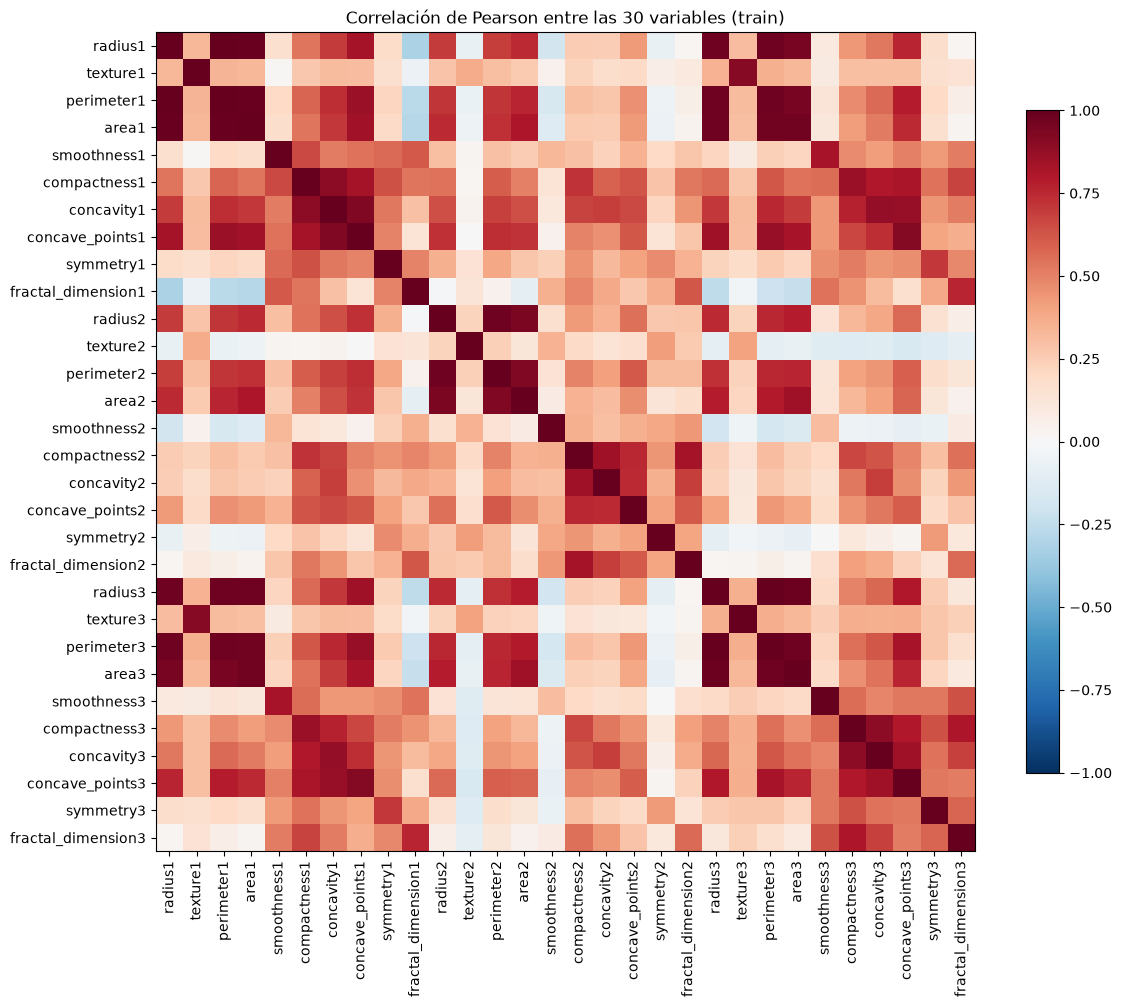

In [5]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(30)); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(30)); ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title("Correlación de Pearson entre las 30 variables (train)")
plt.tight_layout(); plt.show()

In [6]:
# Radio, perímetro y área: ¿miden lo mismo?
for suf, nombre in [("1", "media"), ("2", "error estándar"), ("3", "peor")]:
    sub = corr.loc[[f"radius{suf}", f"perimeter{suf}", f"area{suf}"], [f"radius{suf}", f"perimeter{suf}", f"area{suf}"]]
    print(f"Resumen '{nombre}':")
    display(sub)

# Media vs "peor" de la misma medida
medidas = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
           "concavity", "concave_points", "symmetry", "fractal_dimension"]
mvp = pd.DataFrame({
    "media~peor": [corr.loc[f"{m}1", f"{m}3"] for m in medidas],
    "media~error_std": [corr.loc[f"{m}1", f"{m}2"] for m in medidas],
}, index=medidas)
display(mvp)

Resumen 'media':


,radius1,perimeter1,area1
radius1,1.000,0.998,0.987
perimeter1,0.998,1.000,0.986
area1,0.987,0.986,1.000


Resumen 'error estándar':


,radius2,perimeter2,area2
radius2,1.000,0.970,0.945
perimeter2,0.970,1.000,0.923
area2,0.945,0.923,1.000


Resumen 'peor':


,radius3,perimeter3,area3
radius3,1.000,0.994,0.982
perimeter3,0.994,1.000,0.977
area3,0.982,0.977,1.000


,media~peor,media~error_std
radius,0.975,0.698
texture,0.910,0.373
perimeter,0.976,0.711
area,0.969,0.810
smoothness,0.827,0.332
compactness,0.865,0.726
concavity,0.879,0.691
concave_points,0.915,0.622
symmetry,0.705,0.470
fractal_dimension,0.762,0.619


In [7]:
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("r").reset_index())
pares = pares.loc[pares["r"].abs() >= 0.9].sort_values("r", key=abs, ascending=False)
print(f"Pares con |r| >= 0.90: {len(pares)} de {30 * 29 // 2}")
display(pares)

dist = 1 - corr.abs().values
grupos = hierarchy.fcluster(hierarchy.linkage(dist[np.triu_indices(30, 1)], "average"), t=0.2, criterion="distance")
print("Bloques redundantes (distancia 1-|r| < 0.2):")
for b in pd.Series(corr.columns, index=grupos).groupby(level=0).agg(list):
    if len(b) > 1:
        print("  ", b)

Pares con |r| >= 0.90: 21 de 435


,level_0,level_1,r
2,radius1,perimeter1,0.998
622,radius3,perimeter3,0.994
3,radius1,area1,0.987
63,perimeter1,area1,0.986
623,radius3,area3,0.982
683,perimeter3,area3,0.977
82,perimeter1,perimeter3,0.976
20,radius1,radius3,0.975
80,perimeter1,radius3,0.974
22,radius1,perimeter3,0.970


Bloques redundantes (distancia 1-|r| < 0.2):
   ['texture1', 'texture3']
   ['smoothness1', 'smoothness3']
   ['compactness2', 'concavity2']
   ['compactness3', 'concavity3']
   ['compactness1', 'concavity1', 'concave_points1', 'concave_points3']
   ['radius1', 'perimeter1', 'area1', 'radius3', 'perimeter3', 'area3']
   ['radius2', 'perimeter2', 'area2']


**Redundancia observada**
- **Radio, perímetro y área** son casi la misma información (r ≈ 0.99 en media y en "peor"), lo que es esperable geométricamente (perímetro ∝ radio, área ∝ radio²). Basta un representante por resumen.
- La **media y el "peor"** de una misma medida también están muy correlacionados (r ≈ 0.97 para radio/perímetro/área y ≈ 0.9 para textura y concavidad), así que suelen aportar información parecida.
- `concavity`, `concave_points` y `compactness` forman otro bloque correlacionado (forma del contorno).
- Los **errores estándar** (sufijo 2) están menos correlacionados con las medias, salvo en el bloque de tamaño (`radius2`, `perimeter2`, `area2`).

## 4. Relevancia individual y multivariada (solo train)

In [8]:
F, p_anova = f_classif(X_train, y_train)
mi = mutual_info_classif(X_train, y_train, random_state=SEED)

scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)

# L1: C elegido con CV estratificada dentro de train
l1 = LogisticRegressionCV(Cs=np.logspace(-2, 1, 20), l1_ratios=(1,), solver="liblinear", use_legacy_attributes=True,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1", max_iter=5000)
l1.fit(Z_train, y_train)
coef_l1 = pd.Series(l1.coef_[0], index=X.columns)
print(f"L1: C = {l1.C_[0]:.3f}, variables con coeficiente ≠ 0: {(coef_l1 != 0).sum()}")

# RFE con regresión logística (eliminación recursiva hasta 8 variables)
rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=8).fit(Z_train, y_train)

rel = pd.DataFrame({
    "ANOVA_F": F, "MI": mi, "coef_L1": coef_l1.values, "RFE_rank": rfe.ranking_,
}, index=X.columns)
rel["rank_ANOVA"] = rel["ANOVA_F"].rank(ascending=False)
rel["rank_MI"] = rel["MI"].rank(ascending=False)
rel = rel.sort_values("ANOVA_F", ascending=False)
display(rel)

L1: C = 0.546, variables con coeficiente ≠ 0: 10


,ANOVA_F,MI,coef_L1,RFE_rank,rank_ANOVA,rank_MI
concave_points3,575.592,0.436,0.000,13,1.0,5.0
perimeter3,539.160,0.448,0.000,1,2.0,4.0
concave_points1,533.037,0.456,2.457,1,3.0,2.0
radius3,517.155,0.457,0.883,1,4.0,1.0
perimeter1,429.967,0.415,0.000,10,5.0,6.0
radius1,402.343,0.381,0.000,3,6.0,7.0
area3,386.711,0.449,2.951,1,7.0,3.0
area1,353.575,0.375,0.000,8,8.0,8.0
concavity1,325.497,0.347,0.000,1,9.0,9.0
concavity3,230.803,0.290,0.108,9,10.0,11.0


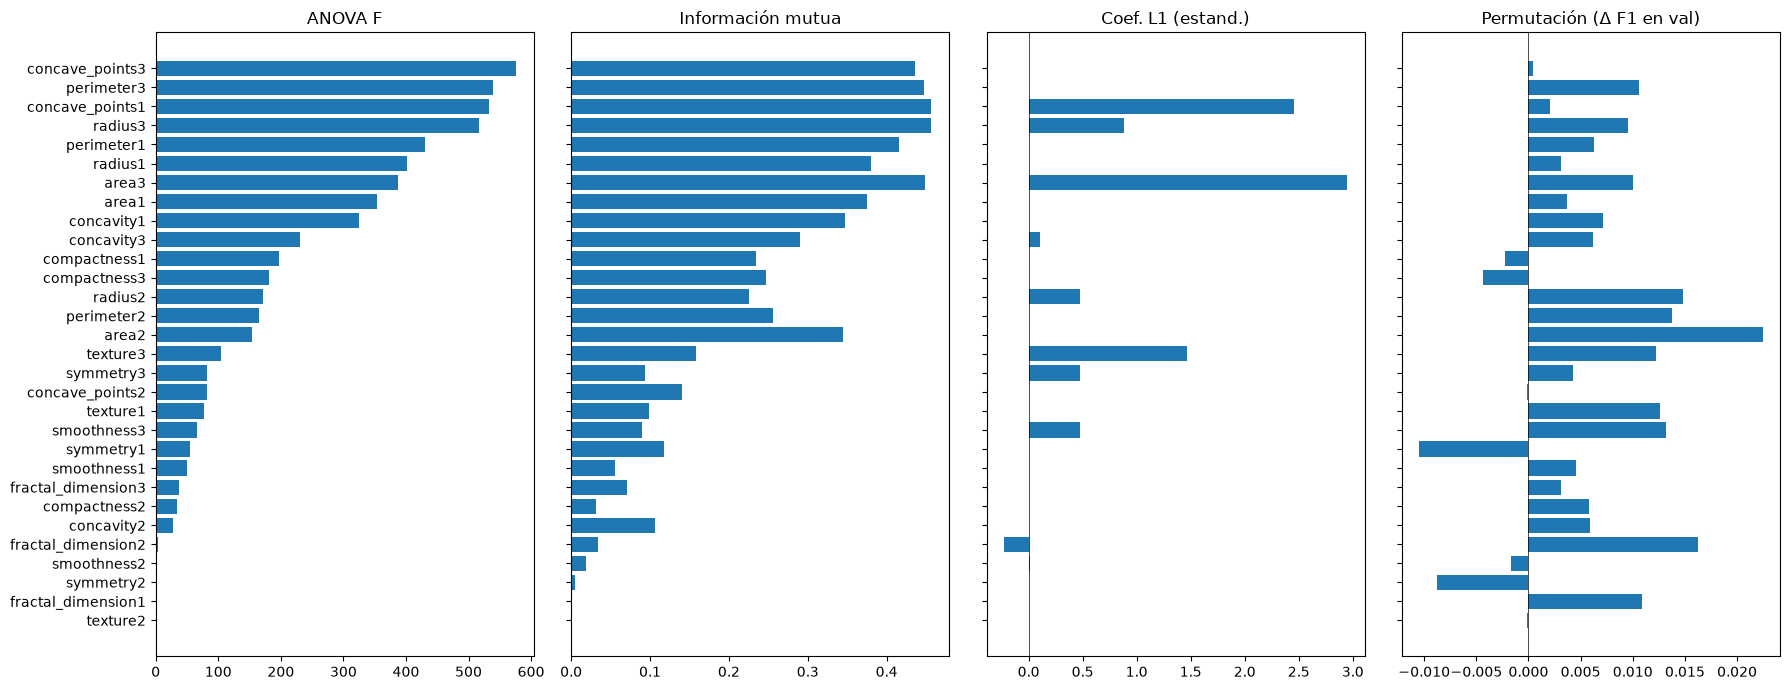

In [9]:
def rna(semilla=SEED):
    # Arquitectura fija para todo el experimento (la del código inicial)
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                              max_iter=1000, random_state=semilla)),
    ])

todas = list(X.columns)
rna_todas = rna().fit(X_train[todas], y_train)
perm = permutation_importance(rna_todas, X_val[todas], y_val, n_repeats=20,
                              random_state=SEED, scoring="f1")
rel["perm_F1"] = pd.Series(perm.importances_mean, index=todas)

fig, axes = plt.subplots(1, 4, figsize=(18, 7), sharey=True)
orden = rel.index[::-1]
for ax, (col, tit) in zip(axes, [("ANOVA_F", "ANOVA F"), ("MI", "Información mutua"),
                                 ("coef_L1", "Coef. L1 (estand.)"), ("perm_F1", "Permutación (Δ F1 en val)")]):
    ax.barh(orden, rel.loc[orden, col]); ax.set_title(tit); ax.axvline(0, color="k", lw=.5)
plt.tight_layout(); plt.show()

**Lectura**
- ANOVA e información mutua coinciden en el top: `concave_points3`, `perimeter3`, `radius3`, `area3`, `concave_points1`, `perimeter1`… Pero ese top está **lleno de redundancia**: hay tres versiones del tamaño y dos de los puntos cóncavos.
- L1 hace una selección **multivariada**: se queda con pocas variables y, dentro de cada bloque correlacionado, conserva una o dos (por ejemplo `radius3` en lugar de radio, perímetro y área). Incorpora `texture3` y variables de forma (`smoothness3`, `symmetry3`) que individualmente no están arriba pero aportan información **complementaria**.
- La importancia por permutación de la RNA completa es pequeña para cada variable: si se "rompe" una, la red usa otra correlacionada que trae lo mismo. Es otra manifestación de la redundancia.

## 5. Subconjuntos candidatos

Todos se construyen con train únicamente.

In [10]:
def sin_redundancia(orden, umbral=0.9, k=10, corr_abs=None):
    # Recorre el ranking y agrega una variable solo si |r| < umbral con todas las ya elegidas
    corr_abs = X_train.corr().abs() if corr_abs is None else corr_abs
    sel = []
    for c in orden:
        if all(corr_abs.loc[c, s] < umbral for s in sel):
            sel.append(c)
        if len(sel) == k:
            break
    return sel

subconjuntos = {
    "A_todas": todas,
    "B_ANOVA_top10": list(rel["ANOVA_F"].sort_values(ascending=False).index[:10]),
    "C_ANOVA_sin_redund": sin_redundancia(rel["ANOVA_F"].sort_values(ascending=False).index),
    "D_MI_sin_redund": sin_redundancia(rel["MI"].sort_values(ascending=False).index),
    "E_L1": list(coef_l1[coef_l1 != 0].index),
    "F_RFE8": list(X.columns[rfe.support_]),
}
for k, v in subconjuntos.items():
    print(f"{k:20s} ({len(v):2d}): {v if k != 'A_todas' else '…las 30…'}")

A_todas              (30): …las 30…
B_ANOVA_top10        (10): ['concave_points3', 'perimeter3', 'concave_points1', 'radius3', 'perimeter1', 'radius1', 'area3', 'area1', 'concavity1', 'concavity3']
C_ANOVA_sin_redund   (10): ['concave_points3', 'perimeter3', 'concavity1', 'concavity3', 'compactness1', 'compactness3', 'radius2', 'texture3', 'symmetry3', 'concave_points2']
D_MI_sin_redund      (10): ['radius3', 'concave_points1', 'area2', 'concavity3', 'compactness3', 'compactness1', 'texture3', 'concave_points2', 'symmetry1', 'concavity2']
E_L1                 (10): ['concave_points1', 'radius2', 'smoothness2', 'fractal_dimension2', 'radius3', 'texture3', 'area3', 'smoothness3', 'concavity3', 'symmetry3']
F_RFE8               ( 8): ['concavity1', 'concave_points1', 'radius2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3']


- **B — ANOVA top‑10**: filtro univariado puro (sirve para mostrar el efecto de la redundancia).
- **C — ANOVA sin redundancia**: mismo ranking, pero descarta variables con |r| ≥ 0.9 respecto de una ya elegida.
- **D — IM sin redundancia**: igual que C con información mutua (captura relaciones no lineales).
- **E — L1**: regresión logística con penalización L1 (C elegido por CV en train).
- **F — RFE‑8**: eliminación recursiva con regresión logística hasta 8 variables.

## 6. Comparación con la misma arquitectura y particiones

### 6.1 Validación fija (train → val), varias semillas

Con 114 casos de validación (43 malignos), **un** falso negativo más cambia el recall en 2.3 puntos. Por eso además de la semilla 42 se repite con 5 semillas de inicialización.

In [11]:
def metricas(y_true, pred):
    cm = confusion_matrix(y_true, pred)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "FN": cm[1, 0], "FP": cm[0, 1]}

semillas = [SEED, 0, 1, 2, 3]
filas = []
for nombre, vars_ in subconjuntos.items():
    for s in semillas:
        m = rna(s).fit(X_train[vars_], y_train)
        filas.append({"subconjunto": nombre, "semilla": s, "n_vars": len(vars_),
                      **metricas(y_val, m.predict(X_val[vars_]))})
res_val = pd.DataFrame(filas)

print("Validación, semilla 42:")
display(res_val[res_val["semilla"] == SEED].set_index("subconjunto").drop(columns="semilla"))
print("Validación, media sobre 5 semillas (FN y FP = promedio de casos):")
display(res_val.groupby("subconjunto").agg(n_vars=("n_vars", "first"), accuracy=("accuracy", "mean"),
        recall=("recall", "mean"), F1=("F1", "mean"), F1_std=("F1", "std"), FN=("FN", "mean"), FP=("FP", "mean")))

Validación, semilla 42:


,n_vars,accuracy,precision,recall,F1,FN,FP
subconjunto,,,,,,,
A_todas,30,0.965,0.933,0.977,0.955,1,3
B_ANOVA_top10,10,0.974,0.976,0.953,0.965,2,1
C_ANOVA_sin_redund,10,0.974,0.955,0.977,0.966,1,2
D_MI_sin_redund,10,0.965,0.933,0.977,0.955,1,3
E_L1,10,0.974,0.955,0.977,0.966,1,2
F_RFE8,8,0.974,0.955,0.977,0.966,1,2


Validación, media sobre 5 semillas (FN y FP = promedio de casos):


,n_vars,accuracy,recall,F1,F1_std,FN,FP
subconjunto,,,,,,,
A_todas,30,0.970,0.977,0.961,0.010,1.0,2.4
B_ANOVA_top10,10,0.974,0.953,0.965,0.000,2.0,1.0
C_ANOVA_sin_redund,10,0.979,0.981,0.972,0.006,0.8,1.6
D_MI_sin_redund,10,0.963,0.977,0.952,0.005,1.0,3.2
E_L1,10,0.970,0.972,0.961,0.010,1.2,2.2
F_RFE8,8,0.967,0.958,0.956,0.005,1.8,2.0


### 6.2 Estabilidad: validación cruzada estratificada repetida sobre train + val

Para tener una estimación menos ruidosa se usa CV estratificada 5×5 sobre el conjunto de desarrollo (train + val, **sin tocar prueba**). En cada fold el **método de selección se vuelve a ajustar dentro del `Pipeline`**, solo con los datos de entrenamiento del fold, así no hay fuga de información de selección. Esto evalúa los *métodos*, no una lista fija.

In [12]:
class SinRedundancia(BaseEstimator, TransformerMixin):
    # Ranking por un puntaje univariado + filtro de redundancia, ajustado solo con los datos que recibe en fit
    def __init__(self, score="anova", k=10, umbral=0.9):
        self.score, self.k, self.umbral = score, k, umbral

    def fit(self, X, y):
        Xd = pd.DataFrame(X)
        s = f_classif(Xd, y)[0] if self.score == "anova" else mutual_info_classif(Xd, y, random_state=SEED)
        corr_abs = Xd.corr().abs().values
        sel = []
        for j in np.argsort(-s):
            if all(corr_abs[j, i] < self.umbral for i in sel):
                sel.append(j)
            if len(sel) == self.k:
                break
        self.sel_ = np.array(sorted(sel))
        self.n_features_in_ = Xd.shape[1]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.sel_]

    def get_support(self):
        mask = np.zeros(self.n_features_in_, bool)
        mask[self.sel_] = True
        return mask


def con_selector(selector):
    # Misma RNA; el selector se ajusta dentro de cada fold (después del escalado)
    return Pipeline([("scaler", StandardScaler()), ("sel", selector),
                     ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                                           max_iter=1000, random_state=SEED))])

metodos = {
    "A_todas": rna(),
    "B_ANOVA_top10": con_selector(SelectKBest(f_classif, k=10)),
    "C_ANOVA_sin_redund": con_selector(SinRedundancia("anova", k=10)),
    "D_MI_sin_redund": con_selector(SinRedundancia("mi", k=10)),
    "E_L1": con_selector(SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=l1.C_[0]))),
    "F_RFE8": con_selector(RFE(LogisticRegression(max_iter=5000), n_features_to_select=8)),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "F1": "f1"}
cv_res, cv_est = {}, {}
for nombre, modelo in metodos.items():
    out = cross_validate(modelo, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=-1, return_estimator=True)
    cv_res[nombre] = {f"{m}_{a}": getattr(out[f"test_{m}"], a)() for m in scoring for a in ("mean", "std")}
    cv_est[nombre] = out["estimator"]

tabla_cv = pd.DataFrame(cv_res).T
tabla_cv.insert(0, "n_vars", [len(subconjuntos[k]) for k in tabla_cv.index])
display(tabla_cv.sort_values("recall_mean", ascending=False))

,n_vars,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,F1_mean,F1_std
D_MI_sin_redund,10,0.973,0.014,0.974,0.026,0.954,0.033,0.964,0.020
E_L1,10,0.969,0.015,0.968,0.030,0.951,0.031,0.958,0.020
A_todas,30,0.974,0.013,0.981,0.024,0.948,0.028,0.964,0.018
C_ANOVA_sin_redund,10,0.969,0.015,0.972,0.026,0.946,0.031,0.958,0.021
F_RFE8,8,0.967,0.016,0.970,0.028,0.940,0.031,0.955,0.022
B_ANOVA_top10,10,0.953,0.017,0.951,0.036,0.922,0.043,0.935,0.023


In [13]:
# Frecuencia con que cada variable fue elegida en los 25 folds (estabilidad de la selección)
# y Jaccard medio entre las selecciones de cada par de folds (1 = siempre las mismas variables)
freq, jaccard = {}, {}
for nombre in ["B_ANOVA_top10", "C_ANOVA_sin_redund", "D_MI_sin_redund", "E_L1", "F_RFE8"]:
    masks = np.array([est.named_steps["sel"].get_support() for est in cv_est[nombre]])
    freq[nombre] = pd.Series(masks.mean(axis=0), index=todas)
    jac = [(a & b).sum() / (a | b).sum() for i, a in enumerate(masks) for b in masks[i + 1:]]
    jaccard[nombre] = {"vars_por_fold": masks.sum(axis=1).mean(), "Jaccard_medio": np.mean(jac)}
freq = (pd.DataFrame(freq) * 100).round(0)
freq = freq.loc[freq.max(axis=1) > 0].sort_values("E_L1", ascending=False)
print("Porcentaje de folds (de 25) en que se eligió cada variable:")
display(freq)
display(pd.DataFrame(jaccard).T)

Porcentaje de folds (de 25) en que se eligió cada variable:


,B_ANOVA_top10,C_ANOVA_sin_redund,D_MI_sin_redund,E_L1,F_RFE8
concave_points1,100.0,4.0,88.0,100.0,92.0
area3,100.0,0.0,8.0,100.0,84.0
smoothness3,0.0,92.0,40.0,100.0,16.0
symmetry3,0.0,88.0,40.0,100.0,4.0
texture3,0.0,100.0,100.0,100.0,100.0
concavity3,92.0,100.0,100.0,100.0,48.0
radius2,0.0,88.0,0.0,96.0,96.0
fractal_dimension2,0.0,0.0,0.0,96.0,4.0
concave_points3,100.0,96.0,12.0,92.0,84.0
radius3,100.0,0.0,20.0,84.0,100.0


,vars_por_fold,Jaccard_medio
B_ANOVA_top10,10.00,0.972
C_ANOVA_sin_redund,10.00,0.811
D_MI_sin_redund,10.00,0.674
E_L1,12.36,0.771
F_RFE8,8.00,0.664


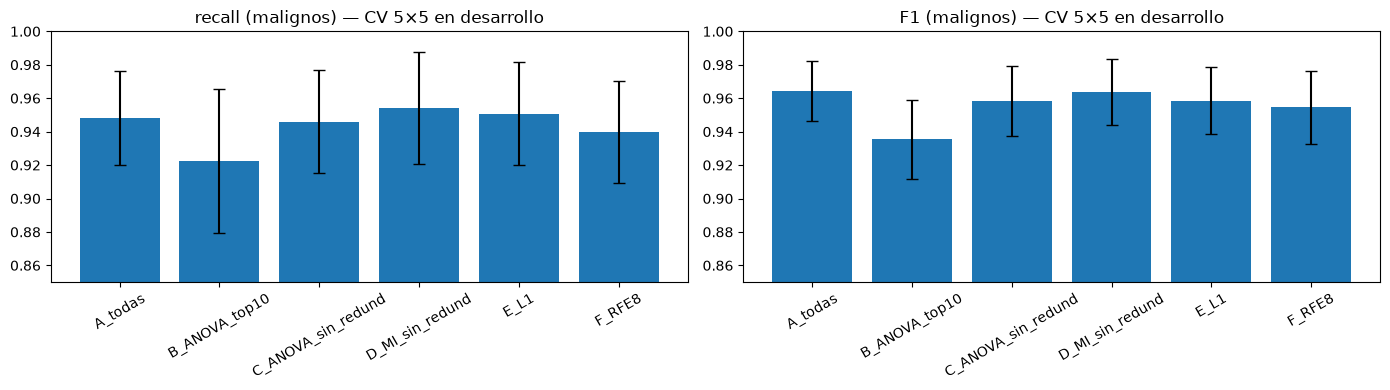

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
orden = tabla_cv.index
for ax, met in zip(axes, ["recall", "F1"]):
    ax.bar(orden, tabla_cv[f"{met}_mean"], yerr=tabla_cv[f"{met}_std"], capsize=4)
    ax.set_ylim(0.85, 1.0); ax.set_title(f"{met} (malignos) — CV 5×5 en desarrollo")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### Discusión de la comparación

**Desempeño.** Todas las RNA rinden muy alto (accuracy ≈ 0.95–0.98): el problema es "fácil" y la información diagnóstica está repartida en muchas variables correlacionadas. Las diferencias entre subconjuntos son del orden de **un caso** de validación y quedan dentro del desvío de la CV, así que no hay que sobreinterpretarlas. Aun así hay patrones claros:

- **B (ANOVA top‑10 con redundancia) es el peor** en CV: recall 0.922 contra 0.948 de "todas". Sus 10 variables son en realidad 3–4 conceptos (tamaño ×6, concavidad ×4) y se pierde la textura y la forma. Quedarse con el top‑k de un ranking univariado sin filtrar redundancia es una mala estrategia.
- **C, D y E (10 variables sin redundancia)** igualan al modelo con 30 variables en CV (F1 0.958–0.964 contra 0.964; recall 0.946–0.954 contra 0.948). Con un tercio de las variables se mantiene el desempeño.
- En la validación fija, **C** tiene el mejor promedio: recall 0.981, F1 0.972 y 0.8 malignos no detectados por corrida (contra 1.0 de "todas").

**Estabilidad de la selección** (Jaccard entre folds). B es "estable" porque siempre elige el mismo bloque redundante. Entre los métodos sin redundancia, **C es el más estable (0.81)**, seguido por L1 (0.76; además su tamaño varía entre 10 y 14 variables), mientras que IM (0.67) y RFE (0.66) cambian bastante de un fold a otro. Variables como `texture3`, `concavity3`, `concave_points3` y `perimeter3` aparecen casi siempre en C.

**Selección final: C — ANOVA + filtro de redundancia (|r| < 0.9), 10 variables**:
`concave_points3`, `perimeter3`, `concavity1`, `concavity3`, `compactness1`, `compactness3`, `radius2`, `texture3`, `symmetry3`, `concave_points2`.

Justificación:
1. **Desempeño**: igual al de las 30 variables en CV y el mejor en la validación fija, con la menor cantidad media de falsos negativos.
2. **Estabilidad**: es el método sin redundancia que más repite las mismas variables entre folds.
3. **Cantidad e interpretabilidad**: 10 variables (−67 %), con un representante de cada aspecto del núcleo: tamaño (`perimeter3`, `radius2`), forma/concavidad, textura y simetría.

D (información mutua) tiene un recall de CV apenas mayor (0.954), pero es la selección más inestable y la peor en la validación fija, así que se descarta.

## 7. Evaluación final en prueba (una única vez)

Configuración congelada: misma arquitectura, semilla 42, y la lista final de variables obtenida **con train**. Ambos modelos (30 variables y selección final) se reentrenan con train + validación y se evalúan sobre prueba una sola vez.

Variables finales: ['concave_points3', 'perimeter3', 'concavity1', 'concavity3', 'compactness1', 'compactness3', 'radius2', 'texture3', 'symmetry3', 'concave_points2']


,n_vars,accuracy,precision,recall,F1,FN,FP
A_todas,30.0,0.965,1.000,0.905,0.950,4.0,0.0
C_ANOVA_sin_redund,10.0,0.974,0.976,0.952,0.964,2.0,1.0


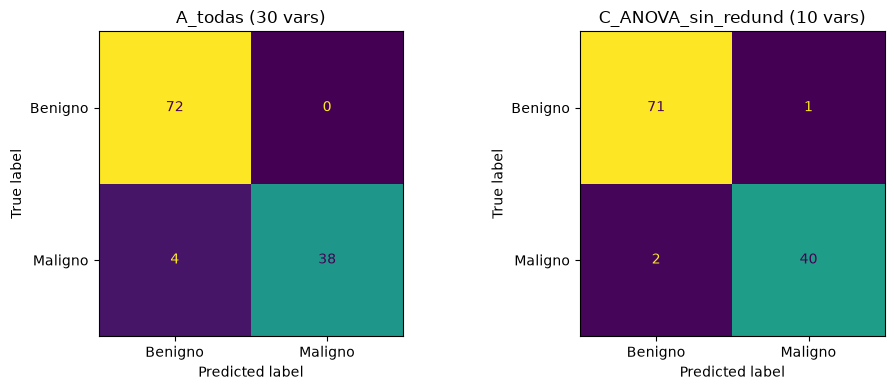

== A_todas
              precision    recall  f1-score   support

     Benigno      0.947     1.000     0.973        72
     Maligno      1.000     0.905     0.950        42

    accuracy                          0.965       114
   macro avg      0.974     0.952     0.961       114
weighted avg      0.967     0.965     0.965       114

== C_ANOVA_sin_redund
              precision    recall  f1-score   support

     Benigno      0.973     0.986     0.979        72
     Maligno      0.976     0.952     0.964        42

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114



In [15]:
nombre_final = "C_ANOVA_sin_redund"
seleccion_final = subconjuntos[nombre_final]
print("Variables finales:", seleccion_final)

filas, preds = {}, {}
for nombre in ["A_todas", nombre_final]:
    vars_ = subconjuntos[nombre]
    m = rna().fit(X_dev[vars_], y_dev)
    preds[nombre] = m.predict(X_test[vars_])
    filas[nombre] = {"n_vars": len(vars_), **metricas(y_test, preds[nombre])}
display(pd.DataFrame(filas).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nombre in zip(axes, preds):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[nombre]),
                           display_labels=["Benigno", "Maligno"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{nombre} ({len(subconjuntos[nombre])} vars)")
plt.tight_layout(); plt.show()

for nombre in preds:
    print(f"== {nombre}")
    print(classification_report(y_test, preds[nombre], target_names=["Benigno", "Maligno"], digits=3))

## 8. Conclusiones

**Resultado en prueba** (114 casos, 42 malignos, evaluado una única vez):

| Modelo | Variables | Accuracy | Precisión | Recall (malignos) | F1 | Malignos no detectados |
|---|---|---|---|---|---|---|
| RNA con todas | 30 | 0.965 | 1.000 | 0.905 | 0.950 | **4** |
| RNA selección final (C) | 10 | 0.974 | 0.976 | 0.952 | 0.964 | **2** |

Con un tercio de las variables, la RNA mantiene (e incluso mejora levemente) el desempeño: detecta **2 malignos más** a cambio de **1 falso positivo**, un intercambio conveniente cuando el error grave es el falso negativo. La diferencia en prueba (2 casos) es consistente con lo visto en validación, aunque en CV ambos modelos quedaron empatados. La lectura más prudente es que **la selección no empeora y simplifica mucho el modelo**, no que lo mejore de forma garantizada.

**Redundancia.** Es el rasgo dominante del dataset: radio, perímetro y área son casi la misma variable (r ≈ 0.99), y la media y el "peor" de cada medida están muy correlacionados. Por eso el top‑10 de un ranking univariado (B) fue el peor subconjunto: elige muchas copias de la misma información. Filtrar redundancia antes de cortar el ranking fue la decisión que más mejoró la selección.

**Estabilidad.** Los resultados cambian ±2–3 puntos de recall según el fold, lo que equivale a uno o dos pacientes. Con datasets de este tamaño conviene decidir con validación cruzada repetida y mirar qué tan seguido se repiten las variables, no con una sola partición. El subconjunto final fue el más estable entre los métodos sin redundancia.

**Cuidados metodológicos.** Se excluyó el `ID`, la partición es estratificada, el escalado está dentro del `Pipeline`, los rankings se calcularon solo con train, en la CV la selección se reajustó dentro de cada fold y la prueba se usó una sola vez, con la lista ya congelada. La arquitectura, la semilla y las particiones fueron las mismas para todos los subconjuntos.

**Limitaciones.** El umbral de decisión quedó en 0.5. Si el objetivo fuera minimizar falsos negativos, el siguiente paso sería bajar el umbral (elegido en validación) para subir el recall a costa de precisión. Recordar que es un ejercicio educativo y no una herramienta clínica.